In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [28]:
import os

for d in os.listdir("/kaggle/input"):
    print("DATASET:", d)
    base = os.path.join("/kaggle/input", d)
    for root, dirs, files in os.walk(base):
        depth = root[len(base):].count(os.sep)
        if depth <= 3:
            print("  " * depth, os.path.basename(root), "| folders:", len(dirs), "| files:", len(files))

DATASET: datasets
 datasets | folders: 2 | files: 0
   minhhuy2810 | folders: 1 | files: 0
     rice-diseases-image-dataset | folders: 2 | files: 0
       LabelledRice | folders: 1 | files: 0
       RiceDiseaseDataset | folders: 2 | files: 0
   abdallahalidev | folders: 1 | files: 0
     plantvillage-dataset | folders: 4 | files: 0
       segmented | folders: 38 | files: 0
       grayscale | folders: 38 | files: 0
       plantvillage dataset | folders: 3 | files: 0
       color | folders: 38 | files: 0


In [34]:
import os

PV   = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset"
RICE = "/kaggle/input/datasets/minhhuy2810/rice-diseases-image-dataset"

IMG = (".jpg", ".jpeg", ".png")

def show(root, max_depth=3):
    for r, dirs, files in os.walk(root):
        depth = r[len(root):].count(os.sep)
        if depth > max_depth:
            dirs[:] = []
            continue
        n_img = sum(f.lower().endswith(IMG) for f in files)
        print("  " * depth + os.path.basename(r), "| images:", n_img, "| subfolders:", len(dirs))

print("======== PLANTVILLAGE (top level) ========")
print(os.listdir(PV))

print("\n======== RICE ========")
show(RICE, max_depth=3)

======== PLANTVILLAGE (top level) ========
['segmented', 'grayscale', 'plantvillage dataset', 'color']

======== RICE ========
rice-diseases-image-dataset | images: 0 | subfolders: 2
  LabelledRice | images: 0 | subfolders: 1
    Labelled | images: 0 | subfolders: 4
      BrownSpot | images: 523 | subfolders: 0
      Healthy | images: 1488 | subfolders: 0
      Hispa | images: 565 | subfolders: 0
      LeafBlast | images: 779 | subfolders: 0
  RiceDiseaseDataset | images: 0 | subfolders: 2
    train | images: 0 | subfolders: 4
      BrownSpot | images: 400 | subfolders: 0
      Healthy | images: 400 | subfolders: 0
      Hispa | images: 400 | subfolders: 0
      LeafBlast | images: 400 | subfolders: 0
    validation | images: 0 | subfolders: 4
      BrownSpot | images: 123 | subfolders: 0
      Healthy | images: 123 | subfolders: 0
      Hispa | images: 123 | subfolders: 0
      LeafBlast | images: 123 | subfolders: 0


In [35]:
COLOR = None
for r, dirs, files in os.walk(PV):
    if os.path.basename(r).lower() == "color":
        COLOR = r
        break
print("COLOR path:", COLOR)

WANT = ["Tomato___Early_blight", "Tomato___Late_blight", "Tomato___Septoria_leaf_spot",
        "Tomato___Leaf_Mold", "Tomato___healthy",
        "Potato___Early_blight", "Potato___Late_blight", "Potato___healthy"]

for cls in sorted(os.listdir(COLOR)):
    if cls in WANT or cls.startswith("Corn"):
        print(cls, "->", len(os.listdir(os.path.join(COLOR, cls))))

COLOR path: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/plantvillage dataset/color
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot -> 513
Corn_(maize)___Common_rust_ -> 1192
Corn_(maize)___Northern_Leaf_Blight -> 985
Corn_(maize)___healthy -> 1162
Potato___Early_blight -> 1000
Potato___Late_blight -> 1000
Potato___healthy -> 152
Tomato___Early_blight -> 1000
Tomato___Late_blight -> 1909
Tomato___Leaf_Mold -> 952
Tomato___Septoria_leaf_spot -> 1771
Tomato___healthy -> 1591


In [44]:
import os, pandas as pd

IMG = (".jpg", ".jpeg", ".png")
PV  = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset"
RICE_LAB = "/kaggle/input/datasets/minhhuy2810/rice-diseases-image-dataset/LabelledRice/Labelled"

# PlantVillage ka color folder dhoondho
COLOR = None
for r, d, f in os.walk(PV):
    if os.path.basename(r).lower() == "color":
        COLOR = r
        break
print("COLOR path:", COLOR)

def norm(s):
    return s.lower().replace(" ", "_")

PV_MAP = {
 "tomato___early_blight": "tomato_early_blight",
 "tomato___late_blight": "tomato_late_blight",
 "tomato___septoria_leaf_spot": "tomato_septoria_leaf_spot",
 "tomato___leaf_mold": "tomato_leaf_mold",
 "tomato___healthy": "tomato_healthy",
 "potato___early_blight": "potato_early_blight",
 "potato___late_blight": "potato_late_blight",
 "potato___healthy": "potato_healthy",
 "corn_(maize)___common_rust_": "maize_common_rust",
 "corn_(maize)___northern_leaf_blight": "maize_northern_leaf_blight",
 "corn_(maize)___cercospora_leaf_spot_gray_leaf_spot": "maize_gray_leaf_spot",
 "corn_(maize)___healthy": "maize_healthy",
}
RICE_MAP = {
 "BrownSpot": "rice_brown_spot",
 "LeafBlast": "rice_leaf_blast",
 "Healthy":   "rice_healthy",
}

rows, matched = [], set()
for cls in os.listdir(COLOR):
    key = norm(cls)
    if key in PV_MAP:
        matched.add(key)
        for fn in os.listdir(os.path.join(COLOR, cls)):
            if fn.lower().endswith(IMG):
                rows.append((os.path.join(COLOR, cls, fn), PV_MAP[key], "plantvillage"))

for cls, label in RICE_MAP.items():
    for fn in os.listdir(os.path.join(RICE_LAB, cls)):
        if fn.lower().endswith(IMG):
            rows.append((os.path.join(RICE_LAB, cls, fn), label, "rice"))

df = pd.DataFrame(rows, columns=["path", "label", "source"])
print(df.label.value_counts().sort_index())
print("\nTotal images:", len(df), "| classes:", df.label.nunique())
print("Not matched (check naming):", set(PV_MAP) - matched)

df.to_csv("/kaggle/working/manifest.csv", index=False)

COLOR path: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/plantvillage dataset/color
label
maize_common_rust             1192
maize_gray_leaf_spot           513
maize_healthy                 1162
maize_northern_leaf_blight     985
potato_early_blight           1000
potato_healthy                 152
potato_late_blight            1000
rice_brown_spot                523
rice_healthy                  1488
rice_leaf_blast                779
tomato_early_blight           1000
tomato_healthy                1591
tomato_late_blight            1909
tomato_leaf_mold               952
tomato_septoria_leaf_spot     1771
Name: count, dtype: int64

Total images: 16017 | classes: 15
Not matched (check naming): set()


In [51]:
import hashlib
from PIL import Image
from sklearn.model_selection import train_test_split

df = pd.read_csv("/kaggle/working/manifest.csv")
print("Start:", len(df))

# 1. corrupt images hatao
def ok(p):
    try:
        with Image.open(p) as im:
            im.verify()
        return True
    except Exception:
        return False

df["ok"] = df.path.apply(ok)
print("Corrupt:", (~df.ok).sum())
df = df[df.ok].drop(columns="ok")

# 2. exact duplicates hatao (md5)
def md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        h.update(f.read())
    return h.hexdigest()

df["md5"] = df.path.apply(md5)
dups = df.duplicated("md5", keep="first").sum()
print("Exact duplicates:", dups)
df = df.drop_duplicates("md5", keep="first")

# agar ek hi photo do alag labels me ho to wo bhi check
conflict = df.groupby("md5").label.nunique()
print("Same photo, multiple labels:", (conflict > 1).sum())

# 3. split (fixed seed)
train, temp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)
val, test   = train_test_split(temp, test_size=0.50, stratify=temp.label, random_state=42)
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"

print(df.pivot_table(index="label", columns="split", values="path", aggfunc="count"))
df.to_csv("/kaggle/working/manifest_clean.csv", index=False)

Start: 16017
Corrupt: 0
Exact duplicates: 14
Same photo, multiple labels: 0
split                       test  train  val
label                                       
maize_common_rust            179    834  179
maize_gray_leaf_spot          77    359   77
maize_healthy                175    813  174
maize_northern_leaf_blight   147    690  148
potato_early_blight          150    700  150
potato_healthy                23    106   23
potato_late_blight           150    700  150
rice_brown_spot               78    366   79
rice_healthy                 223   1042  223
rice_leaf_blast              117    545  117
tomato_early_blight          150    700  150
tomato_healthy               238   1110  237
tomato_late_blight           285   1331  285
tomato_leaf_mold             143    666  143
tomato_septoria_leaf_spot    266   1240  265


In [52]:
!pip install onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 46.8 MB/s  0:00:00 eta 0:00:01


In [53]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [54]:
import torch, torch.nn as nn, numpy as np, pandas as pd, json, time
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from PIL import Image
from sklearn.metrics import f1_score

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

df = pd.read_csv("/kaggle/working/manifest_clean.csv")
classes = sorted(df.label.unique())
c2i = {c: i for i, c in enumerate(classes)}
df["y"] = df.label.map(c2i)
json.dump(classes, open("/kaggle/working/labels.json", "w"), indent=1)

norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),
    T.RandomApply([T.GaussianBlur(5, (0.1, 2.0))], p=0.2),
    T.ToTensor(), norm])
eval_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, d, tf): self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        return self.tf(Image.open(r.path).convert("RGB")), r.y

tr, va, te = [df[df.split == s] for s in ("train", "val", "test")]
dl_tr = DataLoader(DS(tr, train_tf), batch_size=64, shuffle=True,  num_workers=2, pin_memory=True)
dl_va = DataLoader(DS(va, eval_tf),  batch_size=64, shuffle=False, num_workers=2)
dl_te = DataLoader(DS(te, eval_tf),  batch_size=64, shuffle=False, num_workers=2)

cnt = tr.y.value_counts().sort_index().values
w = torch.tensor((cnt.sum() / cnt) ** 0.5, dtype=torch.float32)
w = (w / w.mean()).to(dev)
print(len(tr), len(va), len(te), "| classes:", len(classes))

device: cuda
11202 2400 2401 | classes: 15


In [55]:
model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(classes))
model = model.to(dev)

total = sum(p.numel() for p in model.parameters())
print("total params:", f"{total:,}")

crit = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))

def run_epoch(dl, opt=None):
    train = opt is not None
    model.train(train)
    ys, ps, tot = [], [], 0.0
    for x, y in dl:
        x, y = x.to(dev), y.to(dev)
        with torch.set_grad_enabled(train), torch.autocast(dev, enabled=(dev == "cuda")):
            out = model(x); loss = crit(out, y)
        if train:
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * len(y)
        ys += y.tolist(); ps += out.argmax(1).tolist()
    return tot / len(ys), f1_score(ys, ps, average="macro")

best = 0
def fit(epochs, lr, freeze_backbone):
    global best
    for p in model.features.parameters(): p.requires_grad = not freeze_backbone
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    for e in range(epochs):
        t = time.time()
        trl, trf = run_epoch(dl_tr, opt); sch.step()
        with torch.no_grad(): val_l, val_f = run_epoch(dl_va)
        print(f"ep{e+1}/{epochs} train_loss {trl:.3f} f1 {trf:.3f} | val_loss {val_l:.3f} f1 {val_f:.3f} | {time.time()-t:.0f}s")
        if val_f > best:
            best = val_f; torch.save(model.state_dict(), "/kaggle/working/best.pt")

fit(2, 1e-3, freeze_backbone=True)    # sirf last layer
fit(5, 1e-4, freeze_backbone=False)   # poora fine-tune
print("best val macro-F1:", round(best, 4))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 240MB/s]

total params: 4,221,247


ep1/2 train_loss 1.181 f1 0.770 | val_loss 1.028 f1 0.842 | 180s
ep2/2 train_loss 0.983 f1 0.859 | val_loss 0.973 f1 0.867 | 171s
ep1/5 train_loss 0.885 f1 0.912 | val_loss 0.849 f1 0.926 | 175s
ep2/5 train_loss 0.811 f1 0.944 | val_loss 0.805 f1 0.941 | 176s
ep3/5 train_loss 0.776 f1 0.955 | val_loss 0.780 f1 0.947 | 175s
ep4/5 train_loss 0.759 f1 0.960 | val_loss 0.772 f1 0.950 | 176s
ep5/5 train_loss 0.750 f1 0.963 | val_loss 0.768 f1 0.952 | 175s
best val macro-F1: 0.9521


                            precision    recall  f1-score   support

         maize_common_rust      1.000     1.000     1.000       179
      maize_gray_leaf_spot      0.912     0.948     0.930        77
             maize_healthy      1.000     1.000     1.000       175
maize_northern_leaf_blight      0.972     0.946     0.959       147
       potato_early_blight      0.993     1.000     0.997       150
            potato_healthy      1.000     1.000     1.000        23
        potato_late_blight      1.000     0.980     0.990       150
           rice_brown_spot      0.797     0.808     0.803        78
              rice_healthy      0.902     0.946     0.923       223
           rice_leaf_blast      0.857     0.769     0.811       117
       tomato_early_blight      0.974     0.980     0.977       150
            tomato_healthy      1.000     0.996     0.998       238
        tomato_late_blight      0.973     0.993     0.983       285
          tomato_leaf_mold      0.993     0.979

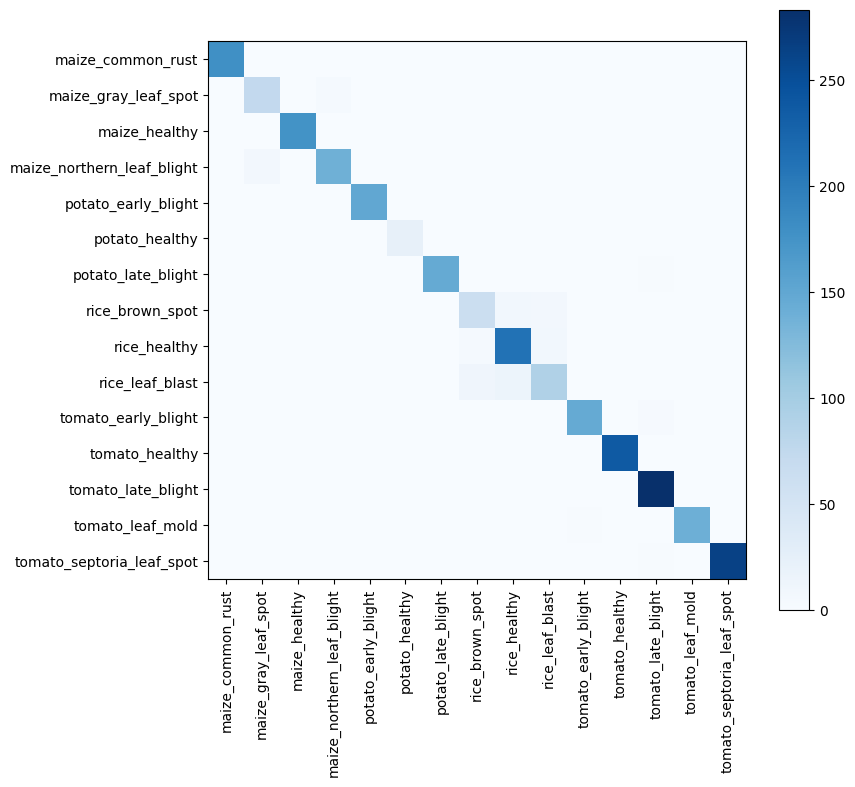

source
plantvillage    0.986889
rice            0.870813
dtype: float64


/tmp/ipykernel_49/3611798029.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(te2.groupby("source").apply(lambda g: (g.y == g.pred).mean()))


In [56]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

model.load_state_dict(torch.load("/kaggle/working/best.pt")); model.eval()
ys, ps = [], []
with torch.no_grad():
    for x, y in dl_te:
        ps += model(x.to(dev)).argmax(1).cpu().tolist(); ys += y.tolist()

print(classification_report(ys, ps, target_names=classes, digits=3))

cm = confusion_matrix(ys, ps)
plt.figure(figsize=(9, 8)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(classes)), classes, rotation=90); plt.yticks(range(len(classes)), classes)
plt.colorbar(); plt.tight_layout(); plt.show()

te2 = te.reset_index(drop=True).assign(pred=ps)
print(te2.groupby("source").apply(lambda g: (g.y == g.pred).mean()))

In [58]:
import torch
import torch.nn as nn
import os

# Check trained model
print("=== MODEL DETAILS ===")

for name, obj in globals().items():
    if isinstance(obj, nn.Module):
        print("Model variable:", name)
        print("Architecture:", type(obj).__name__)

# Check saved files
print("\n=== SAVED MODEL FILES ===")

for f in os.listdir("/kaggle/working"):
    print(f)

=== MODEL DETAILS ===
Model variable: norm
Architecture: Normalize
Model variable: model
Architecture: MobileNetV3
Model variable: crit
Architecture: CrossEntropyLoss

=== SAVED MODEL FILES ===
.virtual_documents
manifest_clean.csv
best.pt
manifest.csv
labels.json


In [59]:
import torch

# 1. Model architecture
print("Model:", type(model).__name__)

# 2. Model output dimensions
model.eval()

device = next(model.parameters()).device
print("Device:", device)

# 3. Model classifier details
print("\nModel Classifier:")
print(model.classifier)

# 4. Check checkpoint
checkpoint = torch.load(
    "/kaggle/working/best.pt",
    map_location="cpu",
    weights_only=True
)

print("\nCheckpoint Type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint Keys:", list(checkpoint.keys()))

# 5. Check labels
import json

with open("/kaggle/working/labels.json", "r") as f:
    labels = json.load(f)

print("\nNumber of Classes:", len(labels))
print("Labels:", labels)

Model: MobileNetV3
Device: cuda:0

Model Classifier:
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=15, bias=True)
)

Checkpoint Type: <class 'collections.OrderedDict'>
Checkpoint Keys: ['features.0.0.weight', 'features.0.1.weight', 'features.0.1.bias', 'features.0.1.running_mean', 'features.0.1.running_var', 'features.0.1.num_batches_tracked', 'features.1.block.0.0.weight', 'features.1.block.0.1.weight', 'features.1.block.0.1.bias', 'features.1.block.0.1.running_mean', 'features.1.block.0.1.running_var', 'features.1.block.0.1.num_batches_tracked', 'features.1.block.1.0.weight', 'features.1.block.1.1.weight', 'features.1.block.1.1.bias', 'features.1.block.1.1.running_mean', 'features.1.block.1.1.running_var', 'features.1.block.1.1.num_batches_tracked', 'features.2.block.0.0.weight', 'features.2.block.0.1.weight', 'features.2.block.0.1.bias', 'features.2.block.0.

In [60]:
# Check dataset transformations

print("=== DATASET TRANSFORMS ===")

for name, obj in globals().copy().items():
    if "dataset" in name.lower():
        if hasattr(obj, "transform"):
            print(f"\n{name}:")
            print(obj.transform)

# Check normalization
print("\n=== NORMALIZATION ===")
print(norm)

# Check model input/output
print("\n=== MODEL CHECK ===")

model.eval()

print("Model:", type(model).__name__)
print("Output classes:", model.classifier[3].out_features)

=== DATASET TRANSFORMS ===

=== NORMALIZATION ===
Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

=== MODEL CHECK ===
Model: MobileNetV3
Output classes: 15


In [65]:
print(norm)

Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])


In [66]:
import torch

model.eval()

dummy_input = torch.randn(1, 3, 224, 224).to(device)

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Number of classes:", output.shape[1])

Input shape: torch.Size([1, 3, 224, 224])
Output shape: torch.Size([1, 15])
Number of classes: 15


In [69]:
import torch
import os

model.eval()

# Create dummy input
dummy_input = torch.randn(1, 3, 224, 224).to(device)

# Export model
onnx_path = "/kaggle/working/crop_disease_model.onnx"

torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    }
)

print("ONNX Export Successful!")
print("Saved at:", onnx_path)
print("File size:", round(os.path.getsize(onnx_path) / (1024 * 1024), 2), "MB")

ModuleNotFoundError: No module named 'onnxscript'

In [70]:
!pip install onnx onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 3.2 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [onnxscript]2 [onnxscript]


In [71]:
import onnx
import onnxscript

print("ONNX version:", onnx.__version__)
print("ONNXScript installed successfully!")

ONNX version: 1.23.2
ONNXScript installed successfully!


In [72]:
import torch
import os

model.eval()

dummy_input = torch.randn(1, 3, 224, 224).to(device)

onnx_path = "/kaggle/working/crop_disease_model.onnx"

torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    }
)

print("ONNX Export Successful!")
print("File exists:", os.path.exists(onnx_path))
print("File size:", round(os.path.getsize(onnx_path) / (1024 * 1024), 2), "MB")

/tmp/ipykernel_49/1963337193.py:10: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1123 16:50:59.051000 49 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX Export Successful!
File exists: True
File size: 0.33 MB


In [73]:
import onnx

onnx_path = "/kaggle/working/crop_disease_model.onnx"

# Load ONNX model
onnx_model = onnx.load(onnx_path)

# Check model validity
onnx.checker.check_model(onnx_model)

print("ONNX Model is VALID!")

# Model information
print("IR Version:", onnx_model.ir_version)

print("\nInput:")
for inp in onnx_model.graph.input:
    print(inp.name)

print("\nOutput:")
for out in onnx_model.graph.output:
    print(out.name)

print("\nOpset:")
for opset in onnx_model.opset_import:
    print(opset.version)

ONNX Model is VALID!
IR Version: 10

Input:
input

Output:
output

Opset:
18


In [74]:
!pip install onnxruntime

In [75]:
import torch
import onnxruntime as ort
import numpy as np

# Load ONNX model
onnx_path = "/kaggle/working/crop_disease_model.onnx"

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# Create test input
dummy_input = torch.randn(1, 3, 224, 224).to(device)

# PyTorch prediction
model.eval()

with torch.no_grad():
    pytorch_output = model(dummy_input).cpu().numpy()

# ONNX prediction
onnx_input = dummy_input.cpu().numpy()

onnx_output = session.run(
    ["output"],
    {"input": onnx_input}
)[0]

# Compare predictions
print("PyTorch Output Shape:", pytorch_output.shape)
print("ONNX Output Shape:", onnx_output.shape)

print("\nPyTorch Predicted Class:", np.argmax(pytorch_output))
print("ONNX Predicted Class:", np.argmax(onnx_output))

# Numerical difference
difference = np.max(np.abs(pytorch_output - onnx_output))

print("\nMaximum Absolute Difference:", difference)

if np.allclose(pytorch_output, onnx_output, atol=1e-4):
    print("\nSUCCESS: Both models produce matching outputs!")
else:
    print("\nWARNING: Outputs do not match!")

PyTorch Output Shape: (1, 15)
ONNX Output Shape: (1, 15)

PyTorch Predicted Class: 8
ONNX Predicted Class: 8

Maximum Absolute Difference: 2.3841858e-06

SUCCESS: Both models produce matching outputs!


In [78]:
# Check transformations used in dataset

print("Checking available transforms:\n")

for name, obj in globals().copy().items():
    if "transform" in name.lower() or "trans" in name.lower():
        if callable(obj):
            print(f"\nVariable Name: {name}")
            print(obj)

Checking available transforms:



In [79]:
# Check dataset and dataloader variables

for name, obj in globals().copy().items():
    if any(x in name.lower() for x in ["dataset", "loader", "train", "test"]):
        print(name, ":", type(obj))

__loader__ : <class 'NoneType'>
train_test_split : <class 'function'>
train : <class 'pandas.core.frame.DataFrame'>
test : <class 'pandas.core.frame.DataFrame'>
Dataset : <class 'type'>
DataLoader : <class 'type'>
train_tf : <class 'torchvision.transforms.transforms.Compose'>


In [80]:
print("Training Transformations:")
print(train_tf)

Training Transformations:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.6, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.7, 1.3), hue=(-0.05, 0.05))
    RandomApply(
    p=0.2
    GaussianBlur(kernel_size=(5, 5), sigma=(0.1, 2.0))
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [81]:
from torchvision import transforms

inference_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print(inference_tf)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [82]:
import os

# Check test dataset columns
print("Test Dataset Columns:")
print(test.columns)

# Display first 5 rows
display(test.head())

Test Dataset Columns:
Index(['path', 'label', 'source', 'md5'], dtype='object')


,path,label,source,md5
4698,/kaggle/input/datasets/abdallahalidev/plantvil...,tomato_early_blight,plantvillage,6985957a955e8ba66ae137a4c2ec707d
11726,/kaggle/input/datasets/abdallahalidev/plantvil...,tomato_leaf_mold,plantvillage,c57ce8c78956fabf38425adb70ca0b17
12519,/kaggle/input/datasets/abdallahalidev/plantvil...,maize_healthy,plantvillage,f2f7fdc45d8ae04b46c70020dcb3dcf9
4155,/kaggle/input/datasets/abdallahalidev/plantvil...,maize_northern_leaf_blight,plantvillage,f6943e1d885dcbaef60f7896c778841f
1864,/kaggle/input/datasets/abdallahalidev/plantvil...,tomato_late_blight,plantvillage,5d366d6fd47e34b97e696bf20e9f5b43


In [83]:
import torch
import numpy as np
import onnxruntime as ort
import json
from PIL import Image

# 1. Load ONNX model
onnx_path = "/kaggle/working/crop_disease_model.onnx"

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# 2. Load class labels
with open("/kaggle/working/labels.json", "r") as f:
    labels = json.load(f)

# 3. Select one actual test image
row = test.iloc[0]

image_path = row["path"]
actual_label = row["label"]

# 4. Open image
image = Image.open(image_path).convert("RGB")

# 5. Apply inference preprocessing
image_tensor = inference_tf(image).unsqueeze(0)

# 6. Convert tensor to NumPy
input_array = image_tensor.numpy()

# 7. ONNX prediction
output = session.run(
    ["output"],
    {"input": input_array}
)[0]

# 8. Get predicted class
probabilities = torch.softmax(
    torch.tensor(output),
    dim=1
).numpy()[0]

predicted_index = np.argmax(probabilities)
predicted_label = labels[predicted_index]
confidence = probabilities[predicted_index] * 100

# 9. Display results
print("Actual Disease:", actual_label)
print("Predicted Disease:", predicted_label)
print("Confidence:", round(confidence, 2), "%")

if actual_label == predicted_label:
    print("\nPrediction: CORRECT")
else:
    print("\nPrediction: INCORRECT")

Actual Disease: tomato_early_blight
Predicted Disease: tomato_early_blight
Confidence: 86.11 %

Prediction: CORRECT


In [84]:
import time
import numpy as np
from PIL import Image

correct = 0
incorrect = 0

start_time = time.time()

sample_data = test.sample(
    n=min(100, len(test)),
    random_state=42
)

for _, row in sample_data.iterrows():

    image = Image.open(row["path"]).convert("RGB")

    image_tensor = inference_tf(image).unsqueeze(0)

    input_array = image_tensor.numpy()

    output = session.run(
        ["output"],
        {"input": input_array}
    )[0]

    predicted_index = np.argmax(output)
    predicted_label = labels[predicted_index]

    actual_label = row["label"]

    if predicted_label == actual_label:
        correct += 1
    else:
        incorrect += 1

end_time = time.time()

accuracy = (correct / len(sample_data)) * 100
total_time = end_time - start_time

print("Total Images:", len(sample_data))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("ONNX Accuracy:", round(accuracy, 2), "%")
print("Total Inference Time:", round(total_time, 2), "seconds")
print("Average Time per Image:", round(total_time / len(sample_data), 4), "seconds")

Total Images: 100
Correct Predictions: 97
Incorrect Predictions: 3
ONNX Accuracy: 97.0 %
Total Inference Time: 2.02 seconds
Average Time per Image: 0.0202 seconds


In [85]:
%%writefile /kaggle/working/inference.py

import onnxruntime as ort
import numpy as np
import json
from PIL import Image
from pathlib import Path


class CropDiseasePredictor:

    def __init__(self, model_path, labels_path):

        # Load ONNX model
        self.session = ort.InferenceSession(
            str(model_path),
            providers=["CPUExecutionProvider"]
        )

        # Get model input/output names
        self.input_name = self.session.get_inputs()[0].name
        self.output_name = self.session.get_outputs()[0].name

        # Load class labels
        with open(labels_path, "r") as f:
            self.labels = json.load(f)

        print("Crop Disease Model Loaded Successfully!")
        print("Total Classes:", len(self.labels))


    def preprocess(self, image_path):

        # Read image
        image = Image.open(image_path).convert("RGB")

        # Resize image
        image = image.resize((224, 224), Image.Resampling.BILINEAR)

        # Convert to NumPy array
        image = np.array(image, dtype=np.float32) / 255.0

        # Normalize
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

        image = (image - mean) / std

        # HWC to CHW
        image = np.transpose(image, (2, 0, 1))

        # Add batch dimension
        image = np.expand_dims(image, axis=0)

        return image.astype(np.float32)


    def predict(self, image_path, top_k=3):

        # Preprocess image
        input_data = self.preprocess(image_path)

        # ONNX inference
        output = self.session.run(
            [self.output_name],
            {self.input_name: input_data}
        )[0]

        # Convert logits to probabilities
        logits = output[0]

        exp_scores = np.exp(logits - np.max(logits))
        probabilities = exp_scores / np.sum(exp_scores)

        # Get top predictions
        top_indices = np.argsort(probabilities)[::-1][:top_k]

        results = []

        for index in top_indices:

            results.append({
                "disease": self.labels[index],
                "confidence": round(
                    float(probabilities[index] * 100), 2
                )
            })

        return results


# Example usage
if __name__ == "__main__":

    MODEL_PATH = "crop_disease_model.onnx"
    LABELS_PATH = "labels.json"

    IMAGE_PATH = "test_image.jpg"

    predictor = CropDiseasePredictor(
        MODEL_PATH,
        LABELS_PATH
    )

    predictions = predictor.predict(IMAGE_PATH)

    print("\nPrediction Results:")

    for i, result in enumerate(predictions, 1):

        print(f"\nRank {i}")
        print("Disease:", result["disease"])
        print("Confidence:", result["confidence"], "%")

Writing /kaggle/working/inference.py


In [86]:
%%writefile /kaggle/working/requirements.txt

onnxruntime
numpy
Pillow

Writing /kaggle/working/requirements.txt


In [89]:
test_image_path = test.iloc[0]["path"]

predictor = CropDiseasePredictor(
    "/kaggle/working/crop_disease_model.onnx",
    "/kaggle/working/labels.json"
)

predictions = predictor.predict(test_image_path)

print("\nTop 3 Predictions:")

for result in predictions:
    print(result)

NameError: name 'CropDiseasePredictor' is not defined

In [96]:
import sys

sys.path.append("/kaggle/working")

from inference import CropDiseasePredictor

In [97]:
test_image_path = test.iloc[0]["path"]

predictor = CropDiseasePredictor(
    "/kaggle/working/crop_disease_model.onnx",
    "/kaggle/working/labels.json"
)

predictions = predictor.predict(test_image_path)

print("\nTop 3 Predictions:")

for result in predictions:
    print(result)

Crop Disease Model Loaded Successfully!
Total Classes: 15

Top 3 Predictions:
{'disease': 'tomato_early_blight', 'confidence': 86.11}
{'disease': 'potato_late_blight', 'confidence': 2.49}
{'disease': 'potato_healthy', 'confidence': 2.11}


In [98]:
import shutil
import os

files = [
    "crop_disease_model.onnx",
    "labels.json",
    "inference.py",
    "requirements.txt"
]

for file in files:
    path = f"/kaggle/working/{file}"
    print(file, ":", os.path.exists(path))

crop_disease_model.onnx : True
labels.json : True
inference.py : True
requirements.txt : True


In [99]:
import os
import shutil

# Create package folder
package_dir = "/kaggle/working/Crop_Disease_Model"

os.makedirs(package_dir, exist_ok=True)

# Required files
files = [
    "crop_disease_model.onnx",
    "labels.json",
    "inference.py",
    "requirements.txt"
]

# Copy files
for file in files:
    shutil.copy(
        f"/kaggle/working/{file}",
        f"{package_dir}/{file}"
    )

# Create ZIP file
shutil.make_archive(
    "/kaggle/working/Crop_Disease_Model",
    "zip",
    "/kaggle/working",
    "Crop_Disease_Model"
)

print("Model package created successfully!")
print("ZIP Path: /kaggle/working/Crop_Disease_Model.zip")

Model package created successfully!
ZIP Path: /kaggle/working/Crop_Disease_Model.zip


In [100]:
import os

print("Working Directory Files:")

for file in os.listdir("/kaggle/working"):
    print(file)

Working Directory Files:
.virtual_documents
inference.py
requirements.txt
Crop_Disease_Model.zip
manifest_clean.csv
__pycache__
best.pt
Crop_Disease_Model
manifest.csv
crop_disease_model.onnx.data
crop_disease_model.onnx
labels.json
